# CS156 — Session 21: Improved Extension from Session 11
## Ames housing prices by neighborhood

**Session 11 Extension (revisited in Session 21 PCW):** Select a city, plot **homicides or housing prices by neighborhood**, describe the observed patterns, and include the visualization code.

**City:** Ames, Iowa. **Dataset:** Kaggle's *House Prices: Advanced Regression Techniques* training data, **1,460 labeled historical sales across 25 neighborhoods** (roughly 2006–2010). This is not current market data.

**Separation from the Session 21 core work:** This notebook is only the **past extension**, while `21_assignment2_prep_contrastive.ipynb` covers the new SetFit-related experiment.

### Data and preprocessing

The original raw training CSV is hosted in this [public GitHub mirror](https://github.com/knaat/Ames-housing/blob/main/train.csv). When `from_raw=True`, our code downloads it, standardizes neighborhood names, converts sale prices to numbers, removes missing/nonpositive prices, and groups by neighborhood. It calculates **median**, **25th percentile**, **75th percentile**, and **sale count** per neighborhood. A validated aggregate CSV in `../data/session21_ames_neighborhood_summary.csv` provides an **offline option**, but by itself does not repeat the record-level cleaning process.

The diagram uses a point for the median and a horizontal band for the middle 50% of prices. These are *grouped price distributions*, not a geographic street map.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

AMES_URL = "https://raw.githubusercontent.com/knaat/Ames-housing/main/train.csv"
SUMMARY_NAME = "session21_ames_neighborhood_summary.csv"

def find_summary_csv():
    candidates = [Path("data") / SUMMARY_NAME,
                  Path("../data") / SUMMARY_NAME]
    if "__file__" in globals():
        candidates.append(Path(__file__).resolve().parent.parent /
                          "data" / SUMMARY_NAME)
    for path in candidates:
        if path.is_file():
            return path
    raise FileNotFoundError(f"Cannot find {SUMMARY_NAME}. Run from repo root.")

def summarize_ames(from_raw=False):
    if from_raw:
        data = pd.read_csv(AMES_URL)
        data["Neighborhood"] = data["Neighborhood"].astype("string").str.strip()
        data["SalePrice"] = pd.to_numeric(data["SalePrice"], errors="coerce")
        data = data.dropna(subset=["Neighborhood", "SalePrice"])
        data = data[data["SalePrice"] > 0]
        summary = data.groupby("Neighborhood")["SalePrice"].agg(
            n="size", median="median",
            q25=lambda s: s.quantile(0.25),
            q75=lambda s: s.quantile(0.75),
        ).reset_index()
        origin = f"Raw Kaggle mirror, {len(data)} valid sales"
    else:
        summary = pd.read_csv(find_summary_csv())
        origin = "Verified, aggregated CSV in data/ (offline)"
    summary = summary.sort_values("median", ascending=False).reset_index(drop=True)
    print(f"Ames source: {origin}")
    print(f"{len(summary)} neighborhoods; {summary['n'].sum()} sales")
    print(summary[["Neighborhood", "n", "median"]].head(3).to_string(index=False))
    return summary

def plot_ames(summary, show=True, save_path=None):
    fig, ax = plt.subplots(figsize=(10, 8))
    y = np.arange(len(summary))
    ax.hlines(y, summary["q25"] / 1000, summary["q75"] / 1000,
              linewidth=5, alpha=0.5, label="Middle 50% of sales")
    ax.scatter(summary["median"] / 1000, y, zorder=3, label="Median")
    ax.set_yticks(y, summary["Neighborhood"])
    ax.invert_yaxis()
    ax.set_xlabel("Sale price (thousands of USD)")
    ax.set_title("Ames, Iowa — historical home sale prices")
    ax.grid(axis="x", alpha=0.2)
    ax.legend(loc="lower right")
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    if show:
        plt.show()
    else:
        plt.close(fig)
    return fig

### Offline illustration and reproducible chart

The next cell loads the committed, validated neighborhood statistics (offline) and plots them. To repeat the original raw-data cleaning/aggregation, change `from_raw=False` to `from_raw=True` (requires internet access).

Ames source: Verified, aggregated CSV in data/ (offline)
25 neighborhoods; 1460 sales
Neighborhood  n   median
     NridgHt 77 315000.0
      NoRidge 41 301500.0
      StoneBr 25 278000.0


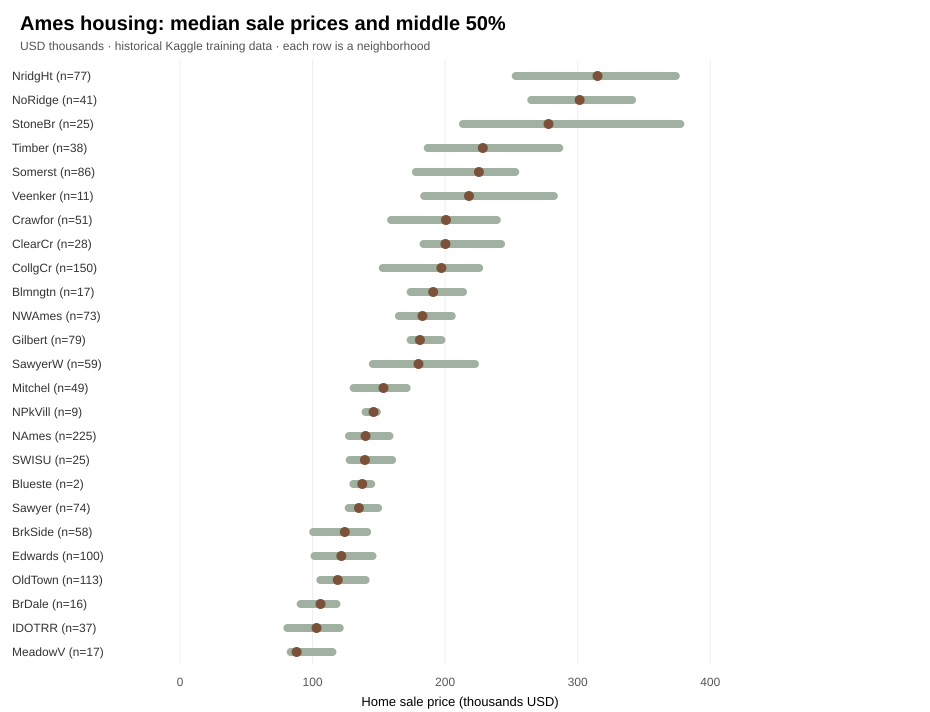

In [2]:
summary = summarize_ames(from_raw=False)
plot_ames(summary)


### Patterns and limitations

- **Northridge Heights (`NridgHt`)** has the highest median (**$315,000**, 77 sales), while **Meadow Village (`MeadowV`)** has the lowest (**$88,000**, 17 sales): a ratio of about **3.58×**.
- The **middle-50% ranges overlap** across neighborhoods: an address alone is a weak explanation of an individual price.
- **Small groups are unstable:** Blueste has only 2 transactions and NPkVill has 9.
- These are **associations**, not causal effects. Sale prices also reflect house size, age, quality, and other covariates. The sample is historical and not appropriate for current valuations.
- This observational geographic comparison should not be misused as a proxy for resident creditworthiness.

**Visualization code** is included in the cell above and in `src/session21_assignment2_prep.py`. The saved chart was prepared from the same validated aggregate values; rerunning the cell generates the matplotlib version.

**References:** De Cock (2011), *Ames, Iowa: Alternative to the Boston Housing Data as an End of Semester Regression Project*; Kaggle housing competition; public CSV mirror linked above.